Experiment	Technique	        Main purpose
Model 1	    No regularization	Establish a baseline
Model 2	    L1 regularization	Encourage some weights to become zero
Model 3	    L2 regularization	Discourage excessively large weights
Model 4	    Dropout	            Reduce reliance on particular neurons
Model 5	    AdamW weight decay	Shrink weights through the optimizer

Regularization does not guarantee better test accuracy in every experiment. The point is to compare the results fairly and see how each method affects overfitting.

# Import the libraries

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.regularizers import L1, L2
from tensorflow.keras.callbacks import EarlyStopping

# Create the dataset

In [48]:
X, y = make_moons(
    n_samples=1000,
    noise=0.30,
    random_state=42
)

In [49]:
# First split the data: 20% testing, 80% development data
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [50]:
# Second split: 60% training, 20% validation
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val)

In [51]:
print("Training examples:", len(X_train))
print("Validation examples:", len(X_val))
print("Test examples:", len(X_test))

Training examples: 600
Validation examples: 200
Test examples: 200


# Scale the input features

In [52]:
scaler = StandardScaler()

In [53]:
# Learn scaling parameters from training data only
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to validation and test data
X_test_scaled = scaler.transform(X_test)
X_val_scaled = scaler.transform(X_val)

# Define a Function to build each model

In [54]:
# The main purpose of this function is to build a neural network whose architecture remains the same, but whose regularization technique changes depending on the value of the technique
def build_model(technique):
    # Setting the random seed: Neural networks initialize their weights with random values. This sets the random seeds used by tensorflow and several other random-number generators
    tf.keras.utils.set_random_seed(42)

    # Creating the neural network
    model = Sequential([
        Input(shape=(2,)),  # 2 Input features per example

        # dense creates a fully connected layer
        Dense(
            128,        # 128 neurons
            activation="relu",
            kernel_regularizer=(                # Optionally penalizes the layer's trainable weights
                L1(1e-5) if technique == "L1"       # 1e-5 is the regularization parameter (lambda)
                else L2(1e-4) if technique == "L2"
                else None
            )
        ),
        # Dropout is active only for the Dropout experiment. With a dropout rate of 0.3, approximately 30% of the layers activations are randomly set to zero during each training step
        Dropout(0.3 if technique == "Dropout" else 0.0),

        Dense(
            128,
            activation="relu",
            kernel_regularizer=(
                L1(1e-5) if technique == "L1"
                else L2(1e-4) if technique == "L2"
                else None
            )
        ),
        Dropout(0.3 if technique == "Dropout" else 0.0),

        # Output layer --> Final layer of Binary classification.
        # 1 means one output neuron
        # Sigmoid converts its output into a value between 0 and 1
        Dense(1, activation="sigmoid")
    ])


    # Choosing the optimizer

    # Use Adam only for the weight-decay experiment
    # AdamW is an adaptive Optimizer with decoupled weight decay
    # learning_rate = 0.001 controls the scale of gradient-based updates
    # weight_decay=1e-4 controls the decay applied to the weights
    if technique == "Weight Decay":
        optimizer = tf.keras.optimizers.AdamW(
            learning_rate=0.001,
            weight_decay=1e-4
        )
    # For Baseline, L1, L2, Dropout, we use:
    else:
        optimizer = tf.keras.optimizers.Adam(
            learning_rate=0.001,
        )

    # Compiling the model
    model.compile(
        optimizer = optimizer,
        loss = "binary_crossentropy",
        metrics = ["accuracy"])

    # Returning the model - This sends the compiled model back to the code that called the function
    return model

# Train all 5 models

This is the part where I train all five neural networks, evaluate their performance, and store their results so I can compare the effects of regularization.

In [55]:
# Define the techniques to compare

# Baseline --> No explicit regularization
# L1 --> Adds an absolute-weight penalty
# L2 --> Adds a squared-weight penalty
# Dropout --> Randomly disables activations during training
# Weight decay --> Uses the AdamW Optimizer
techniques = ["Baseline", "L1", "L2", "Dropout", "Weight Decay"]

In [56]:
models = {}     # Stores the trained neural network for each technique
histories = {}  # Stores the training history, including loss and accuracy after each epoch
results = {}    # Stores the final evaluation metrics for each technique

In [57]:
# Configure early stopping
early_stopping = EarlyStopping(
    patience=15,
    monitor="val_loss",
    restore_best_weights=True
)

In [58]:
# Start the loop
for technique in techniques:
    print("=" * 50)
    print(f"Training: {technique}")
    print("=" * 50)

    # build the current model
    model = build_model(technique)

    # Train the model
    history = model.fit(
        X_train_scaled,
        y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=200,
        batch_size=32,
        callbacks=[early_stopping],
        verbose=0
    )

    # Evaluate the final selected model on training data. After training, you evaluate how well the model performs on the training dataset...
    # The returned values are: train_loss (the loss reported by the model on the training data), and train_accuracy (the fraction of training examples classified correctly)
    train_loss, train_accuracy = model.evaluate(X_train_scaled, y_train, verbose=0)

    # Evaluate on validation data. This measures the performance on the validation dataset, which was not used to calculate training gradients. Validation results help you understand whether the model generalizes beyond the training examples.
    val_loss, val_accuracy = model.evaluate(X_val_scaled, y_val, verbose=0)

    # Evaluate the model on the test data. The test set should not be used to decide the regularization strength or repeatedly tune your model. Otherwise, you risk indirectly adapting your choices to the test set.
    test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)


    # Store the model and history
    models[technique] = model
    histories[technique] = history

    results[technique] = {
        "Train Accuracy": train_accuracy,
        "Validation Accuracy": val_accuracy,
        "Test Accuracy": test_accuracy,
        "Train Loss": train_loss,
        "Validation Loss": val_loss,
        "Test Loss": test_loss,
        "Generalization Gap": train_accuracy - test_accuracy,
        "Epochs Trained": len(history.history["loss"])
    }

    print("Epochs trained:", len(history.history["loss"]))
    print(f"Train accuracy:      {train_accuracy:.2%}")
    print(f"Validation accuracy: {val_accuracy:.2%}")
    print(f"Test accuracy:       {test_accuracy:.2%}")
    print(f"Test loss:            {test_loss:.4f}")

Training: Baseline
Epochs trained: 51
Train accuracy:      91.50%
Validation accuracy: 88.50%
Test accuracy:       94.00%
Test loss:            0.1436
Training: L1
Epochs trained: 15
Train accuracy:      84.17%
Validation accuracy: 80.50%
Test accuracy:       90.50%
Test loss:            0.3739
Training: L2
Epochs trained: 15
Train accuracy:      84.17%
Validation accuracy: 80.50%
Test accuracy:       90.50%
Test loss:            0.3742
Training: Dropout
Epochs trained: 15
Train accuracy:      83.50%
Validation accuracy: 80.50%
Test accuracy:       90.00%
Test loss:            0.3767
Training: Weight Decay
Epochs trained: 15
Train accuracy:      84.17%
Validation accuracy: 80.00%
Test accuracy:       90.50%
Test loss:            0.3614


# Display the results in a table

In [59]:
results_df = pd.DataFrame(results).T

In [60]:
print("\n\nFINAL COMPARISON")
print("=" * 100)

print(results_df.round(4).to_string())



FINAL COMPARISON
              Train Accuracy  Validation Accuracy  Test Accuracy  Train Loss  Validation Loss  Test Loss  Generalization Gap  Epochs Trained
Baseline              0.9150                0.885          0.940      0.1900           0.2528     0.1436             -0.0250            51.0
L1                    0.8417                0.805          0.905      0.4200           0.4432     0.3739             -0.0633            15.0
L2                    0.8417                0.805          0.905      0.4203           0.4435     0.3742             -0.0633            15.0
Dropout               0.8350                0.805          0.900      0.4174           0.4398     0.3767             -0.0650            15.0
Weight Decay          0.8417                0.800          0.905      0.4076           0.4308     0.3614             -0.0633            15.0


# Compare Training and Validation loss Curves

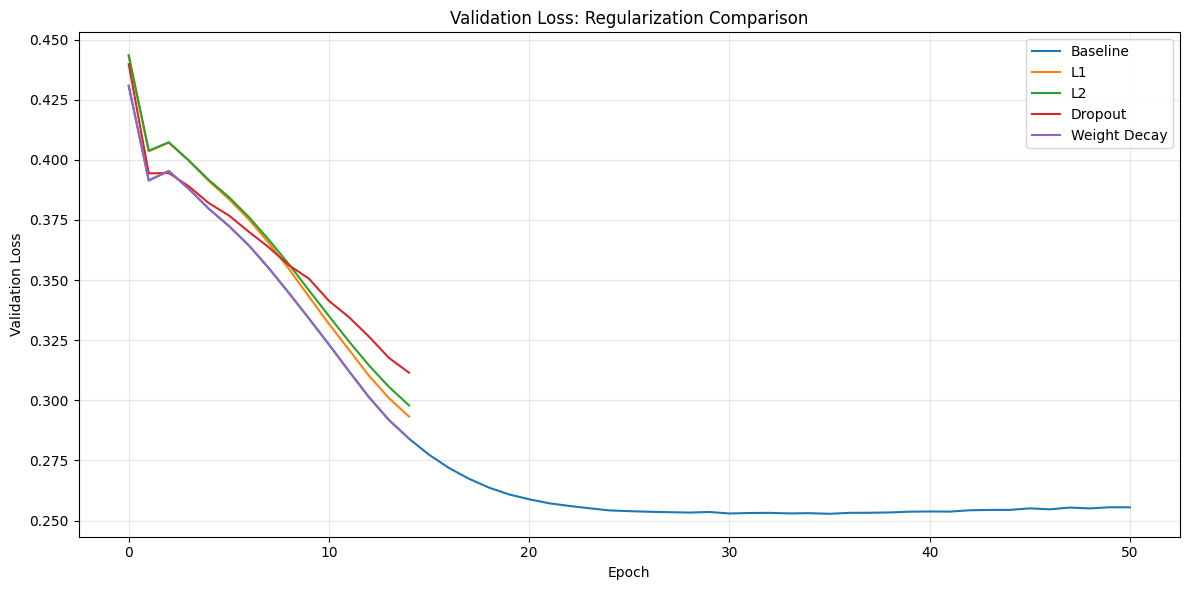

In [61]:
plt.figure(figsize=(12, 6))

for technique in techniques:

    history = histories[technique]

    plt.plot(history.history["val_loss"], label=technique)

plt.title("Validation Loss: Regularization Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Compare Training and Validation accuracy

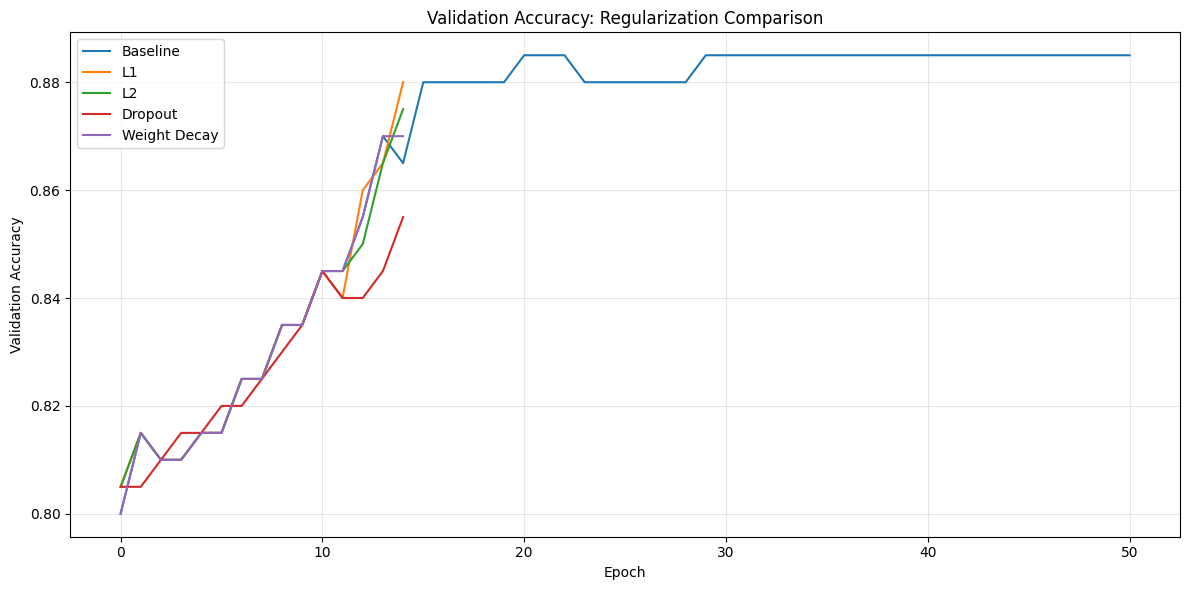

In [62]:
plt.figure(figsize=(12, 6))

for technique in techniques:

    history = histories[technique]

    plt.plot(history.history["val_accuracy"],label=technique)

plt.title("Validation Accuracy: Regularization Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Visualize Training vs Test Accuracy

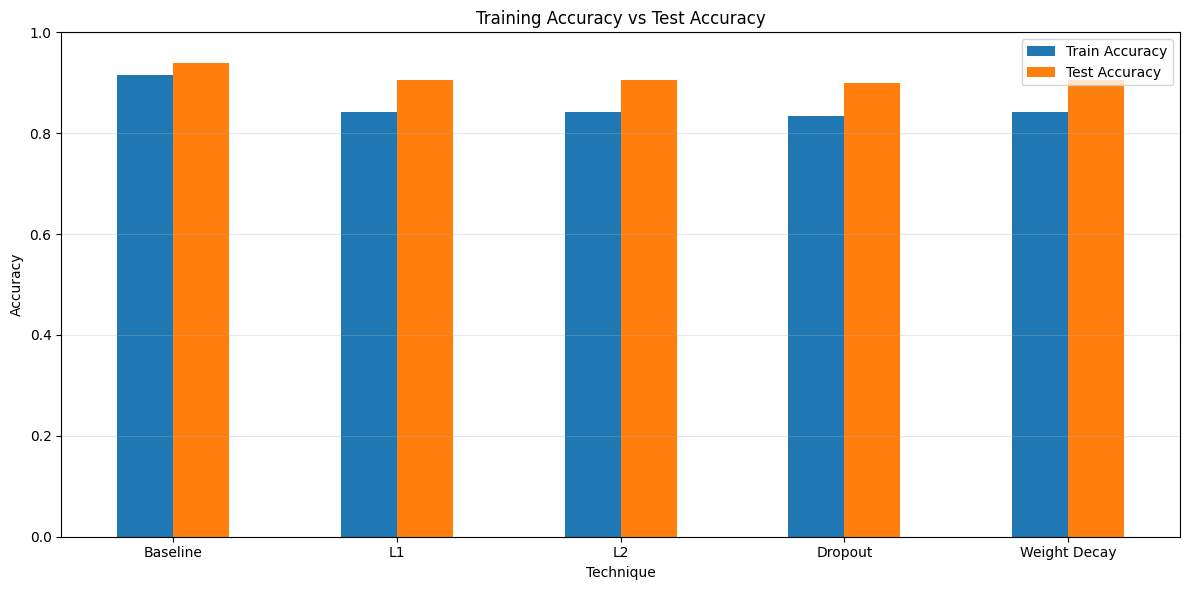

In [63]:
accuracy_comparison = results_df[
    ["Train Accuracy", "Test Accuracy"]
]

accuracy_comparison.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1)
)

plt.title("Training Accuracy vs Test Accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Technique")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Check how many weights are close to zero

In [64]:
print("\nWEIGHT SPARSITY COMPARISON")
print("=" * 50)

for technique, model in models.items():

    # Count kernel weights in Dense layers
    dense_weights = [
        layer.get_weights()[0].flatten()
        for layer in model.layers
        if isinstance(layer, Dense)
    ]

    all_weights = np.concatenate(dense_weights)

    near_zero = np.sum(np.abs(all_weights) < 1e-3)
    total_weights = len(all_weights)

    print(
        f"{technique:12s}: "
        f"{near_zero}/{total_weights} weights near zero "
        f"({near_zero / total_weights:.2%})"
    )



WEIGHT SPARSITY COMPARISON
Baseline    : 108/16768 weights near zero (0.64%)
L1          : 285/16768 weights near zero (1.70%)
L2          : 249/16768 weights near zero (1.48%)
Dropout     : 113/16768 weights near zero (0.67%)
Weight Decay: 100/16768 weights near zero (0.60%)
